# Segmentación de inundaciones con U-Net

El objetivo es entrenar una **U-Net** para segmentar zonas inundadas en imágenes, usando pares imagen-máscara.

La segmentación semántica asigna una clase a cada píxel. En este caso se trabaja con dos clases:

- **0**: fondo / zona no inundada.
- **1**: zona inundada.

Además del entrenamiento, el notebook guarda resultados intermedios para facilitar la revisión del proceso: configuración, métricas, checkpoints, predicciones y visualizaciones.

## 1. Importación de librerías

Se utilizan librerías de PyTorch para construir y entrenar la red neuronal, `torchvision` para transformaciones de imagen, `PIL` para lectura de archivos y `matplotlib` para visualizar resultados.

In [1]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import PIL.Image
import torch
import torch.nn.functional as F
import torchvision
from matplotlib import pyplot as plt
from torch.optim.lr_scheduler import StepLR

## 2. Configuración general

Centralizamos los parámetros principales para que sea sencillo modificar el experimento sin tener que buscar valores dispersos por el notebook.

> Nota: si se dispone de GPU CUDA con memoria suficiente, se puede activar `USAR_GPU = True`. En equipos Apple Silicon se puede usar `mps` si está disponible.

In [2]:
# Rutas de entrada
RUTA_IMAGENES = Path('./data/Image')
RUTA_MASCARAS = Path('./data/Mask')

# Carpeta de salida para resultados intermedios
RUTA_RESULTADOS = Path('./resultados_unet')
RUTA_CHECKPOINTS = RUTA_RESULTADOS / 'checkpoints'
RUTA_PREDICCIONES = RUTA_RESULTADOS / 'predicciones'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'

for carpeta in [RUTA_RESULTADOS, RUTA_CHECKPOINTS, RUTA_PREDICCIONES, RUTA_FIGURAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Hiperparámetros
TAMANIO_IMAGEN = 100
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 0.01
GAMMA_SCHEDULER = 0.5
STEP_SIZE_SCHEDULER = 1
USAR_GPU = True
USAR_MPS = False
SEMILLA = 42

# Selección de dispositivo
if USAR_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
elif USAR_MPS and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f'Dispositivo seleccionado: {device}')

Dispositivo seleccionado: cuda


## 3. Guardado de la configuración del experimento

Guardar la configuración permite reproducir el entrenamiento más adelante y saber exactamente qué parámetros se usaron.

In [3]:
config = {
    'ruta_imagenes': str(RUTA_IMAGENES),
    'ruta_mascaras': str(RUTA_MASCARAS),
    'tamanio_imagen': TAMANIO_IMAGEN,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'learning_rate': LEARNING_RATE,
    'gamma_scheduler': GAMMA_SCHEDULER,
    'step_size_scheduler': STEP_SIZE_SCHEDULER,
    'device': str(device),
    'semilla': SEMILLA,
}

with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

config

{'ruta_imagenes': 'data\\Image',
 'ruta_mascaras': 'data\\Mask',
 'tamanio_imagen': 100,
 'batch_size': 16,
 'epochs': 20,
 'learning_rate': 0.01,
 'gamma_scheduler': 0.5,
 'step_size_scheduler': 1,
 'device': 'cuda',
 'semilla': 42}

## 4. Bloques básicos de la U-Net

La U-Net combina dos caminos:

1. **Encoder o camino de contracción**: reduce la resolución espacial y aprende características cada vez más abstractas.
2. **Decoder o camino de expansión**: recupera la resolución original para producir una máscara píxel a píxel.

Las conexiones laterales, conocidas como **skip connections**, permiten conservar información espacial fina que podría perderse durante la reducción de resolución.

In [4]:
class DoubleConv(torch.nn.Module):
    """Bloque de dos convoluciones consecutivas.

    Cada convolución va seguida de Batch Normalization y ReLU. Este patrón es
    habitual en U-Net porque permite extraer características locales de forma
    progresiva.
    """

    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels

        self.double_conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            torch.nn.BatchNorm2d(mid_channels),
            torch.nn.ReLU(inplace=True),
            torch.nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            torch.nn.BatchNorm2d(out_channels),
            torch.nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class Down(torch.nn.Module):
    """Bloque de reducción (downsample): MaxPool seguido de doble convolución."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.maxpool_conv = torch.nn.Sequential(
            torch.nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels),
        )

    def forward(self, x):
        return self.maxpool_conv(x)


class Up(torch.nn.Module):
    """Bloque de expansión (upsample): aumenta la resolución y concatena la skip connection."""

    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()

        if bilinear: 
            # Con bilinear=True, el modelo aumenta el tamaño espacial de x1 duplicando alto y ancho, pero lo hace con una operación fija, 
            # no aprendida. La interpolación bilineal no aprende pesos. Simplemente calcula nuevos píxeles a partir de los vecinos, como
            # si agrandásemos una imagen 
            # Por tanto, aumenta la resolución de forma fija, no añade parámetros entrenables y suele ser más estable y simple

            self.up = torch.nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            # ConvTranspose2d (convolución transpuesta 2D): aumenta la resolución aprendiendo filtros, añade parámetros entrenables
            # puede aprender mejor el upsampling, pero también puede introducir artefactos (patrones artificiales) si no se entrena adecuadamente, 
            # y suele ser más propenso a sobreajustar en datasets pequeños

            self.up = torch.nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        # x1 procede del decoder; x2 procede del encoder.
        x1 = self.up(x1)

        # Ajuste de tamaño por si hay pequeñas diferencias debidas a redondeos.
        diffY = x2.size()[2] - x1.size()[2] # tamaño en la dimensión de alto ya que la dimensión 0 es el batch, la 1 es el canal, 
                                            # la 2 es el alto y la 3 es el ancho
        diffX = x2.size()[3] - x1.size()[3] # tamaño en la dimensión de ancho

        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2]) # Padding píxeles alrededor de x1 para que tenga el mismo alto y ancho que x2

        # Concatenación de características del encoder y del decoder.
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


class OutConv(torch.nn.Module):
    """Capa final 1x1 que convierte las características en logits de clase."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = torch.nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)

## 5. Definición del modelo U-Net

La salida del modelo son **logits** con dos canales: uno para cada clase. Son “logits crudos”: valores numéricos de salida del modelo antes de convertirlos en probabilidades. Ejemplo de logits por clase:

fondo:     1.2

agua:      3.8

edificio: -0.7

No se aplica `softmax` dentro del modelo porque `CrossEntropyLoss` espera logits sin normalizar.

In [5]:
class UNet(torch.nn.Module):
    """Implementación de U-Net para segmentación binaria."""

    def __init__(self, n_channels, n_classes, bilinear=False): 
        
        '''
        bilinear=False para usar ConvTranspose2d, 
        bilinear=True para usar Upsample (interpolación bilineal)
        La interpolación bilineal es una forma de agrandar una imagen o un mapa de características calculando nuevos valores a partir de los 
        píxeles vecinos.
        '''
        
        super().__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes
        self.bilinear = bilinear

        # Encoder
        self.inc = DoubleConv(n_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        factor = 2 if bilinear else 1
        self.down4 = Down(512, 1024 // factor)

        # Decoder
        self.up1 = Up(1024, 512 // factor, bilinear)
        self.up2 = Up(512, 256 // factor, bilinear)
        self.up3 = Up(256, 128 // factor, bilinear)
        self.up4 = Up(128, 64, bilinear)
        self.outc = OutConv(64, n_classes)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x) # son “logits crudos”: valores numéricos de salida del modelo antes de convertirlos en probabilidades
        return logits

## 6. Funciones auxiliares

Estas funciones hacen el notebook más legible: cargan imágenes, calculan métricas y guardan visualizaciones intermedias.

In [6]:
def cargar_dataset(ruta_imagenes, ruta_mascaras, tamanio=100):
    """Carga imágenes JPG y máscaras PNG asociadas.

    Devuelve:
    - image_tensor: tensor [N, 3, H, W] con valores entre 0 y 1.
    - mask_tensor: tensor [N, H, W] con etiquetas enteras 0/1.
    - nombres_validos: nombres de archivo procesados correctamente.
    """
    imagenes = sorted([f for f in os.listdir(ruta_imagenes) if f.lower().endswith('.jpg')]) 
    # crea una lista ordenada con los nombres de los archivos .jpg que hay dentro de la carpeta ruta_imagenes

    image_tensors = []
    mask_tensors = []
    nombres_validos = []

    for nombre_imagen in imagenes:
        ruta_imagen = ruta_imagenes / nombre_imagen
        nombre_mascara = nombre_imagen.replace('.jpg', '.png')
        ruta_mascara = ruta_mascaras / nombre_mascara

        if not ruta_mascara.exists():
            print(f'Aviso: no se encontró máscara para {nombre_imagen}. Se omite.')
            continue

        imagen = PIL.Image.open(ruta_imagen).convert('RGB') # convierte a RGB la imagen
        imagen = torchvision.transforms.functional.pil_to_tensor(imagen) # convierte a tensor
        imagen = torchvision.transforms.functional.resize(imagen, (tamanio, tamanio)) 
        # redimensionamos a un tamaño fijo para que todas las imágenes tengan el mismo tamaño, lo cual es necesario para procesarlas en batch
        imagen = imagen.float() / 255.0 # normalizamos a [0, 1]

        if imagen.shape != (3, tamanio, tamanio):
            print(f'Aviso: formato inesperado en {nombre_imagen}: {imagen.shape}. Se omite.')
            continue

        mascara = PIL.Image.open(ruta_mascara).convert('L')
        mascara = torchvision.transforms.functional.pil_to_tensor(mascara)
        # Ese bloque prepara la máscara de segmentación para que tenga el tamaño correcto y esté en el formato que espera la red o 
        # la función de pérdida.
        
        mascara = torchvision.transforms.functional.resize(
            mascara,
            (tamanio, tamanio),
            interpolation=torchvision.transforms.InterpolationMode.NEAREST,
        )
        mascara = (mascara[0] > 0).long()

        # El resultado es mascara: (H, W) con valores: 0 o 1

        image_tensors.append(imagen.unsqueeze(0))
        mask_tensors.append(mascara.unsqueeze(0))
        nombres_validos.append(nombre_imagen)

    if not image_tensors:
        raise RuntimeError('No se cargó ninguna imagen válida. Revisa las rutas del dataset.')

    return torch.cat(image_tensors), torch.cat(mask_tensors), nombres_validos


def calcular_iou(pred_mask, true_mask, clase=1, eps=1e-7):
    """
    Calcula IoU/Jaccard para una clase concreta, normalmente la clase inundada
    Como 1 → zona inundada y 0 → fondo, la función suele calcular el IoU de la clase 1, es decir, la clase inundada.
    """
    
    pred_bin = pred_mask == clase # Convierte ambas máscaras en máscaras booleanas para la clase elegida.
    true_bin = true_mask == clase 

    interseccion = (pred_bin & true_bin).sum(dim=(1, 2)).float()
    union = (pred_bin | true_bin).sum(dim=(1, 2)).float()
    return ((interseccion + eps) / (union + eps)).mean().item()


def guardar_visualizacion(epoch, imagen, target, pred_mask, ruta_salida):
    
    """Guarda una figura con imagen original, máscara real, predicción y overlay."""
    imagen_np = imagen.detach().cpu().permute(1, 2, 0).numpy()
    target_np = target.detach().cpu().numpy()
    pred_np = pred_mask.detach().cpu().numpy()

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(imagen_np)
    axes[0].set_title('Imagen original')
    axes[0].axis('off')

    axes[1].imshow(target_np)
    axes[1].set_title('Máscara real')
    axes[1].axis('off')

    axes[2].imshow(pred_np)
    axes[2].set_title('Predicción')
    axes[2].axis('off')

    axes[3].imshow(imagen_np)
    axes[3].imshow(pred_np, alpha=0.35)
    axes[3].set_title('Overlay predicción')
    axes[3].axis('off')

    fig.suptitle(f'Resultados intermedios - época {epoch}')
    fig.tight_layout()
    fig.savefig(ruta_salida, dpi=150, bbox_inches='tight')
    plt.close(fig)

## 7. Carga y exploración inicial del dataset

Cada imagen tiene una máscara asociada. Las imágenes se normalizan a `[0, 1]`; las máscaras se convierten en etiquetas enteras `0` y `1`.

In [7]:
image_tensor, mask_tensor, nombres = cargar_dataset(RUTA_IMAGENES, RUTA_MASCARAS, TAMANIO_IMAGEN)

print('Imágenes:', image_tensor.shape)
print('Máscaras:', mask_tensor.shape)
print('Número de muestras:', len(nombres))

# Guardamos los nombres de las imágenes procesadas para trazabilidad.
with open(RUTA_RESULTADOS / 'imagenes_procesadas.txt', 'w', encoding='utf-8') as f:
    for nombre in nombres:
        f.write(nombre + '')

Imágenes: torch.Size([290, 3, 100, 100])
Máscaras: torch.Size([290, 100, 100])
Número de muestras: 290


## 8. Visualización de una muestra

Antes de entrenar conviene comprobar que las imágenes y las máscaras están bien alineadas.

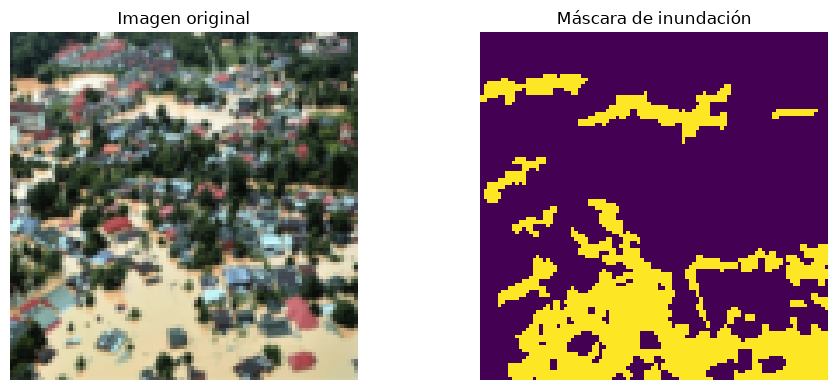

In [8]:
indice = 0
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_tensor[indice].permute(1, 2, 0))
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_tensor[indice])
plt.title('Máscara de inundación')
plt.axis('off')

plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'muestra_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Preparación del entrenamiento

Se crea un `TensorDataset` con imagen y máscara juntas. Esto evita desalineaciones entre dos `DataLoader` separados.

La función de pérdida es `CrossEntropyLoss`, adecuada para segmentación multiclase cuando la máscara contiene índices de clase.

In [9]:
dataset = torch.utils.data.TensorDataset(image_tensor, mask_tensor)
dataloader_train = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

unet = UNet(n_channels=3, n_classes=2).to(device)
optimizer = torch.optim.Adam(unet.parameters(), lr=LEARNING_RATE)
scheduler = StepLR(optimizer=optimizer, step_size=STEP_SIZE_SCHEDULER, gamma=GAMMA_SCHEDULER)
criterion = torch.nn.CrossEntropyLoss()
# aplica log_softmax(logits)y después calcula la pérdida con la clase correcta.

metricas = []
print(unet)

UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 

## 10. Entrenamiento

En cada época se realiza:

1. Predicción de la máscara.
2. Cálculo de la pérdida.
3. Retropropagación.
4. Actualización de pesos.
5. Evaluación con IoU/Jaccard.
6. Guardado de resultados intermedios.

In [10]:
for epoch in range(1, EPOCHS + 1):
    unet.train()
    running_loss = 0.0

    for images_batch, masks_batch in dataloader_train:
        images_batch = images_batch.to(device)
        masks_batch = masks_batch.to(device)

        optimizer.zero_grad()
        logits = unet(images_batch)
        loss = criterion(logits, masks_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Evaluación simple sobre el mismo conjunto de entrenamiento.
    unet.eval()
    iou_epoch = []
    with torch.no_grad():
        for images_batch, masks_batch in dataloader_train:
            images_batch = images_batch.to(device)
            masks_batch = masks_batch.to(device)

            logits = unet(images_batch)
            pred_mask = torch.argmax(logits, dim=1) # para cada píxel, elegir la clase con mayor logit.
            iou_epoch.append(calcular_iou(pred_mask.cpu(), masks_batch.cpu(), clase=1))

    mean_iou = float(np.mean(iou_epoch))
    lr_actual = optimizer.param_groups[0]['lr'] # leer el learning rate actual que está usando el optimizador.

    metricas.append({
        'epoch': epoch,
        'loss': running_loss,
        'iou_clase_inundada': mean_iou,
        'learning_rate': lr_actual,
    })

    print(f'Época {epoch:02d}/{EPOCHS} | pérdida={running_loss:.4f} | IoU inundación={mean_iou:.4f} | lr={lr_actual:.6f}')

    # Guardado de checkpoint del modelo.
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': unet.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'metricas': metricas,
        'config': config,
    }
    torch.save(checkpoint, RUTA_CHECKPOINTS / f'unet_flood_epoch_{epoch:03d}.pt')

    # Guardado de una predicción intermedia para inspección visual.
    with torch.no_grad():
        muestra_img = image_tensor[0:1].to(device)
        logits_muestra = unet(muestra_img)
        pred_muestra = torch.argmax(logits_muestra, dim=1)[0]

    torch.save(pred_muestra.cpu(), RUTA_PREDICCIONES / f'prediccion_epoch_{epoch:03d}.pt')
    guardar_visualizacion(
        epoch,
        image_tensor[0],
        mask_tensor[0],
        pred_muestra.cpu(),
        RUTA_FIGURAS / f'visualizacion_epoch_{epoch:03d}.png',
    )

    scheduler.step()

# Guardado de métricas al terminar.
df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(RUTA_RESULTADOS / 'metricas_entrenamiento.csv', index=False)
df_metricas.tail()

Época 01/20 | pérdida=9.8807 | IoU inundación=0.0298 | lr=0.010000
Época 02/20 | pérdida=8.0472 | IoU inundación=0.4966 | lr=0.005000
Época 03/20 | pérdida=7.3895 | IoU inundación=0.5181 | lr=0.002500
Época 04/20 | pérdida=7.2635 | IoU inundación=0.6071 | lr=0.001250
Época 05/20 | pérdida=7.1890 | IoU inundación=0.5808 | lr=0.000625
Época 06/20 | pérdida=6.7644 | IoU inundación=0.6517 | lr=0.000313
Época 07/20 | pérdida=6.7988 | IoU inundación=0.6414 | lr=0.000156
Época 08/20 | pérdida=6.6377 | IoU inundación=0.6501 | lr=0.000078
Época 09/20 | pérdida=6.8517 | IoU inundación=0.6570 | lr=0.000039
Época 10/20 | pérdida=6.9863 | IoU inundación=0.6590 | lr=0.000020
Época 11/20 | pérdida=6.7115 | IoU inundación=0.6582 | lr=0.000010
Época 12/20 | pérdida=6.8052 | IoU inundación=0.6529 | lr=0.000005
Época 13/20 | pérdida=6.7438 | IoU inundación=0.6540 | lr=0.000002
Época 14/20 | pérdida=6.6684 | IoU inundación=0.6543 | lr=0.000001
Época 15/20 | pérdida=6.6097 | IoU inundación=0.6539 | lr=0.00

,epoch,loss,iou_clase_inundada,learning_rate
15,16,6.847186,0.664971,3.051758e-07
16,17,6.594579,0.655786,1.525879e-07
17,18,6.810069,0.658725,7.629395e-08
18,19,6.734458,0.660017,3.814697e-08
19,20,6.735151,0.655052,1.907349e-08


## 11. Curvas de entrenamiento

Las curvas ayudan a diagnosticar si el modelo está aprendiendo y si la tasa de aprendizaje resulta demasiado agresiva o demasiado baja.

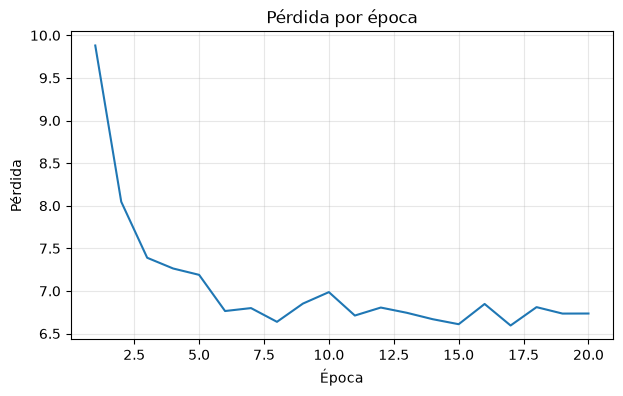

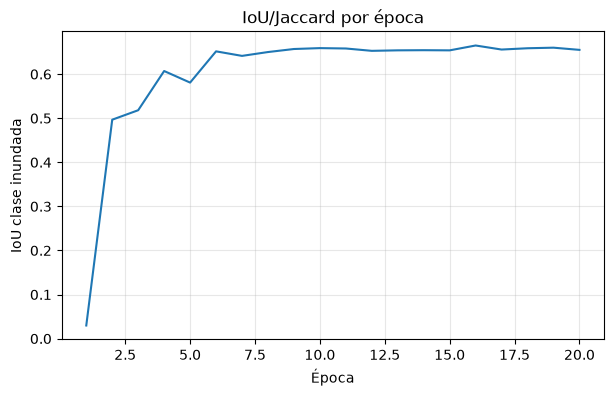

In [11]:
df_metricas = pd.read_csv(RUTA_RESULTADOS / 'metricas_entrenamiento.csv')

plt.figure(figsize=(7, 4))
plt.plot(df_metricas['epoch'], df_metricas['loss'])
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.title('Pérdida por época')
plt.grid(True, alpha=0.3)
plt.savefig(RUTA_FIGURAS / 'curva_perdida.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(df_metricas['epoch'], df_metricas['iou_clase_inundada'])
plt.xlabel('Época')
plt.ylabel('IoU clase inundada')
plt.title('IoU/Jaccard por época')
plt.grid(True, alpha=0.3)
plt.savefig(RUTA_FIGURAS / 'curva_iou.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Visualización final

Mostramos una predicción final sobre una imagen del conjunto de entrenamiento. En un proyecto real convendría separar datos de entrenamiento, validación y test.

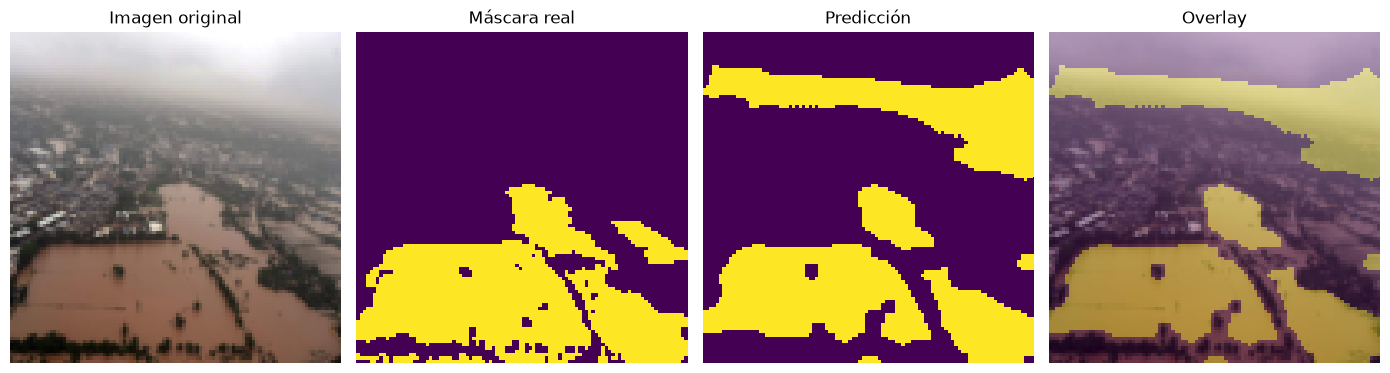

In [12]:
unet.eval()
indice = min(2, len(image_tensor) - 1)

with torch.no_grad():
    imagen = image_tensor[indice:indice+1].to(device)
    logits = unet(imagen)
    pred = torch.argmax(logits, dim=1)[0].cpu()

ruta_final = RUTA_FIGURAS / 'comparacion_final.png'
guardar_visualizacion(EPOCHS, image_tensor[indice], mask_tensor[indice], pred, ruta_final)

img_np = image_tensor[indice].permute(1, 2, 0).numpy()
mask_np = mask_tensor[indice].numpy()
pred_np = pred.numpy()

plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_np)
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(mask_np)
plt.title('Máscara real')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(pred_np)
plt.title('Predicción')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(img_np)
plt.imshow(pred_np, alpha=0.35)
plt.title('Overlay')
plt.axis('off')

plt.tight_layout()
plt.show()

## 13. Qué se ha guardado

El entrenamiento deja una carpeta de resultados con:

- `configuracion.json`: parámetros del experimento.
- `metricas_entrenamiento.csv`: pérdida, IoU y tasa de aprendizaje por época.
- `checkpoints/`: pesos del modelo y estado del optimizador por época.
- `predicciones/`: máscaras predichas intermedias en formato `.pt`.
- `figuras/`: visualizaciones del dataset, evolución y comparación final.

Este esquema facilita comparar experimentos y reutilizar el modelo entrenado sin repetir todo el entrenamiento.